Data berhasil dimuat. Ukuran data: (30000, 15)

Data dibagi: Data Latih=24000, Data Uji=6000

KLASTERING K-MEANS


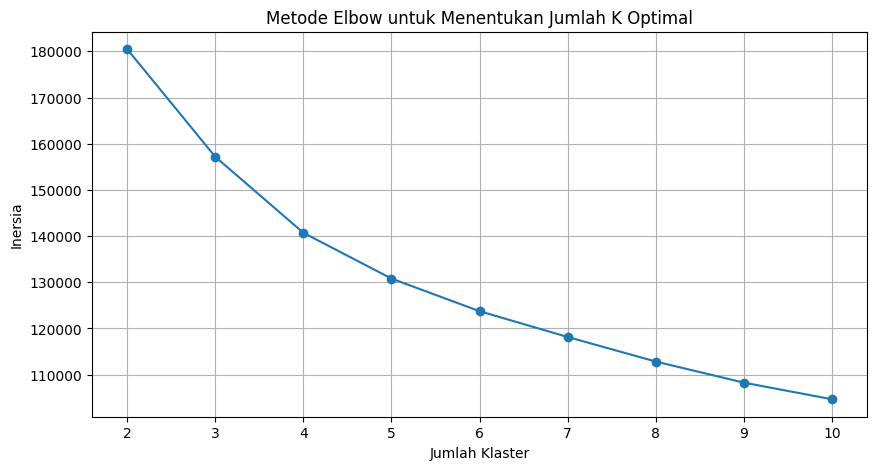


Menggunakan k=4 untuk klastering K-Means
Nilai Silhouette: 0.183


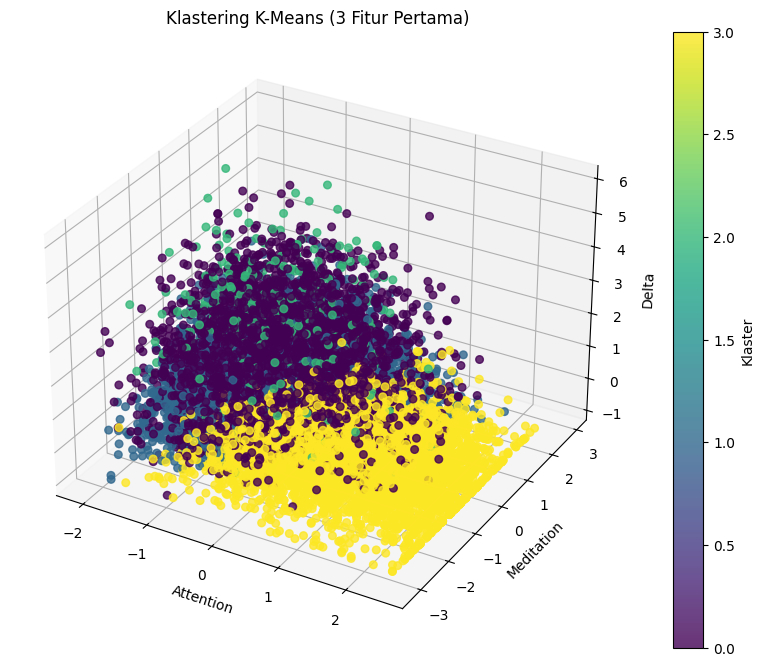


KLASTERING DBSCAN
Jumlah klaster yang ditemukan: 35
Jumlah titik noise: 13029
Nilai Silhouette: -0.431


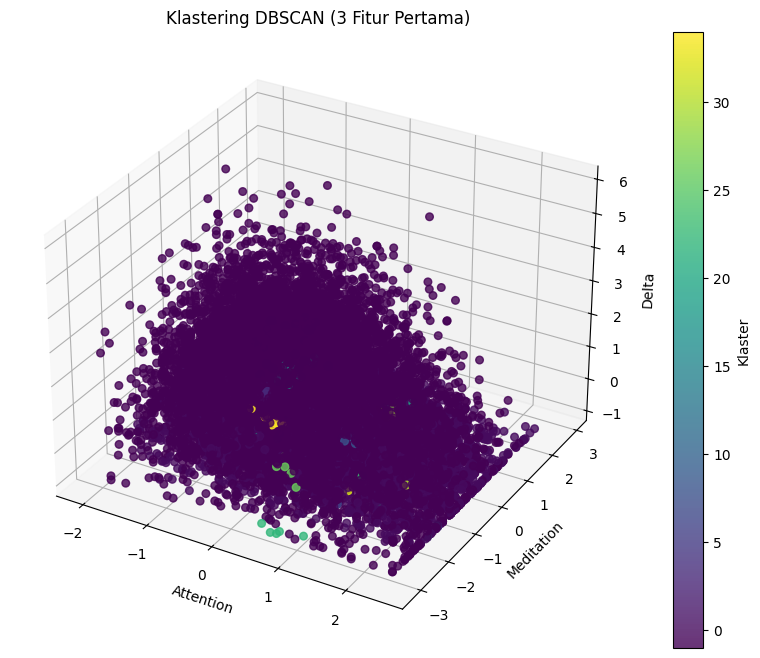


ANALISIS KLASTER

Karakteristik Klaster K-Means:

Klaster 0 (4416 sampel):
Attention          37.0
Meditation         51.0
Delta         1152746.5
Theta          235834.0
Low Alpha       42161.5
High Alpha      30096.5
Low Beta        21598.5
High Beta       45020.0
Low Gamma       38979.5
High Gamma      17841.0
dtype: float64

Klaster 1 (10797 sampel):
Attention         37.0
Meditation        60.0
Delta         184728.0
Theta          41674.0
Low Alpha      10237.0
High Alpha      7704.0
Low Beta        5963.0
High Beta      10650.0
Low Gamma       8459.0
High Gamma      4254.0
dtype: float64

Klaster 2 (465 sampel):
Attention          29.0
Meditation         56.0
Delta         1552073.0
Theta          799779.0
Low Alpha      152097.0
High Alpha     128033.0
Low Beta        90395.0
High Beta       92468.0
Low Gamma       84358.0
High Gamma      38490.0
dtype: float64

Klaster 3 (8322 sampel):
Attention        66.0
Meditation       44.0
Delta         55165.0
Theta         24244.0
Low

In [2]:
# Nama       : Marchell Adi Pratama
# NIM        : 672023081
# Mata Kuliah: Machine Learning

# Import pustaka yang dibutuhkan
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ===============================================
# Catatan untuk Bapak Dosen:
# Mohon maaf, saya telah menyesuaikan path pembacaan dataset
# dari 'c:/all.csv' menjadi 'all.csv' karena kendala teknis saat dijalankan.
# File yang digunakan tetap sama, hanya lokasi akses file disesuaikan
# agar script dapat berjalan dengan baik di lingkungan saya.
# Terima kasih atas pengertiannya.
# ===============================================

# 1. Baca data dari file CSV
try:
    data = pd.read_csv('all.csv')
    print("Data berhasil dimuat. Ukuran data:", data.shape)
except FileNotFoundError:
    print("Kesalahan: File 'all.csv' tidak ditemukan. Silakan periksa lokasi file.")
    exit()
except Exception as e:
    print(f"Kesalahan saat memuat file: {e}")
    exit()

# 2. Pra-pemrosesan data
# Pilih kolom-kolom yang mau dipakai buat clustering
features = [
    'Attention', 'Meditation',
    'Delta', 'Theta',
    'Low Alpha', 'High Alpha',
    'Low Beta', 'High Beta',
    'Low Gamma', 'High Gamma'
]

# Cek dulu apakah semua kolom yang dibutuhkan ada
missing_cols = [col for col in features if col not in data.columns]
if missing_cols:
    print(f"Peringatan: Ada kolom yang hilang {missing_cols}. Pakai fitur yang tersedia saja.")
    features = [col for col in features if col in data.columns]

X = data[features]

# Kalau ada data yang kosong, isi pakai nilai median
if X.isnull().any().any():
    print("Peringatan: Ada data kosong. Diisi median biar aman.")
    X = X.fillna(X.median())

# 3. Bagi data jadi data latih dan data uji (80:20)
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
print(f"\nData dibagi: Data Latih={len(X_train)}, Data Uji={len(X_test)}")

# 4. Normalisasi data biar skala tiap fitur sama
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ===== K-MEANS CLUSTERING =====
print("\n" + "="*40)
print("KLASTERING K-MEANS")
print("="*40)

# Coba beberapa nilai k buat cari yang paling pas (pakai elbow method)
inertia = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_scaled)
    inertia.append(kmeans.inertia_)

# Gambar grafik elbow biar kelihatan titik tekuknya
plt.figure(figsize=(10, 5))
plt.plot(k_range, inertia, marker='o')
plt.title('Metode Elbow untuk Menentukan Jumlah K Optimal')
plt.xlabel('Jumlah Klaster')
plt.ylabel('Inersia')
plt.xticks(k_range)
plt.grid()
plt.show()

# Tentukan jumlah klaster (disesuaikan dari grafik)
optimal_k = 4
print(f"\nMenggunakan k={optimal_k} untuk klastering K-Means")

# Latih model K-Means dengan k yang dipilih
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_train_labels = kmeans.fit_predict(X_train_scaled)
kmeans_test_labels = kmeans.predict(X_test_scaled)

# Cek skor silhouette buat lihat seberapa baik klasternya
silhouette_avg = silhouette_score(X_train_scaled, kmeans_train_labels)
print(f"Nilai Silhouette: {silhouette_avg:.3f}")

# Fungsi buat tampilin hasil klastering dalam 3D
def plot_3d_clusters(X, labels, title):
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')

    scatter = ax.scatter(X[:,0], X[:,1], X[:,2],
                        c=labels, cmap='viridis', s=30, alpha=0.8)

    ax.set_xlabel(features[0])
    ax.set_ylabel(features[1])
    ax.set_zlabel(features[2])
    ax.set_title(title)
    plt.colorbar(scatter, ax=ax, label='Klaster')
    plt.show()

plot_3d_clusters(X_train_scaled[:,:3], kmeans_train_labels,
                'Klastering K-Means (3 Fitur Pertama)')

# ===== DBSCAN CLUSTERING =====
print("\n" + "="*40)
print("KLASTERING DBSCAN")
print("="*40)

# Latih model DBSCAN dengan parameter default (bisa disesuaikan)
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_train_labels = dbscan.fit_predict(X_train_scaled)

# Hitung jumlah klaster dan noise
n_clusters = len(set(dbscan_train_labels)) - (1 if -1 in dbscan_train_labels else 0)
n_noise = list(dbscan_train_labels).count(-1)

print(f"Jumlah klaster yang ditemukan: {n_clusters}")
print(f"Jumlah titik noise: {n_noise}")

# Cek silhouette kalau klasternya lebih dari 1
if n_clusters > 1:
    silhouette_avg = silhouette_score(X_train_scaled, dbscan_train_labels)
    print(f"Nilai Silhouette: {silhouette_avg:.3f}")
else:
    print("Tidak bisa hitung silhouette (hanya satu klaster)")

# Visualisasi hasil DBSCAN
plot_3d_clusters(X_train_scaled[:,:3], dbscan_train_labels,
                'Klastering DBSCAN (3 Fitur Pertama)')

# 5. Analisis hasil klaster
print("\n" + "="*40)
print("ANALISIS KLASTER")
print("="*40)

# Tambahkan label klaster ke data aslinya
cluster_results = X_train.copy()
cluster_results['KMeans_Cluster'] = kmeans_train_labels
cluster_results['DBSCAN_Cluster'] = dbscan_train_labels

# Lihat median dari tiap fitur di tiap klaster K-Means
print("\nKarakteristik Klaster K-Means:")
for cluster in range(optimal_k):
    cluster_data = cluster_results[cluster_results['KMeans_Cluster'] == cluster]
    print(f"\nKlaster {cluster} ({len(cluster_data)} sampel):")
    print(cluster_data[features].median().round(2))

# Kalau ada klaster dari DBSCAN, tampilkan juga
if n_clusters > 0:
    print("\nKarakteristik Klaster DBSCAN:")
    for cluster in sorted(set(dbscan_train_labels)):
        if cluster == -1:
            print("\nTitik Noise:")
        else:
            print(f"\nKlaster {cluster}:")
        cluster_data = cluster_results[cluster_results['DBSCAN_Cluster'] == cluster]
        print(cluster_data[features].median().round(2))
